# **Assignment 2**
## **Convolutional Neural Networks (CNNs) for Image Classification**

In Assignment 1, Mary's neural core learned to read 28 x 28 greyscale handwritten digits using a plain artificial neural network (ANN). Now her cameras are streaming **32 x 32 colour photos of real objects**: planes, ships, frogs, trucks. That is a much harder job, and this is exactly where the simple ANN starts to struggle.

In this assignment we run a fair, head-to-head experiment between the **ANN you already know** and a new kind of network, the **Convolutional Neural Network (CNN)**, which was designed specifically for images. By the end you will know *what* a convolution computes, *why* it suits images, and *how much better* it really is.

> **MISSION LOG - Day 2**
>
> Last week you taught Mary's core to read black and white handwritten digits. Today the engineers' manual says something worrying: the cameras don't see digits, they see the world, and in colour. Mary's old ANN core can look at a photo, but it treats it as one long list of unrelated numbers.
>
> The manual describes a more human way of seeing: slide small pattern detectors across the picture to find edges, then textures, then shapes. **Your job:** install that new vision system, and prove it works better than the old one.

====================================================================================================

### **Before you start**

1) **Save your own copy:** *File → Save a copy in Drive*, and work in that copy.
2) **Turn on a GPU:** *Runtime → Change runtime type → T4 GPU → Save*. We train several models in this assignment. A GPU makes it a few minutes; a CPU can take much longer. You will see which one you are using in Step 2.
3) **Look for the cells marked `TASK`.** Each task asks you to *decide* something, *work something out* (a number, a shape, a parameter count) or *predict* a result. You will **never** be asked to remember syntax. The notebook turns your decisions into code, runs them, and tells you with ✅ or ❌ whether your thinking was right. Every other cell only needs to be run.
4) **Everything you need is explained in the text above the cell.** If a task feels impossible, re-read the Step's explanation: the answer is derivable from it.
5) **Run the cells in order, from top to bottom.** If you skip one, later cells will fail.
6) **If a cell shows an error**, read the *last line* of the error message first. For task cells, it usually tells you exactly what to fix.
7) At the end there are **a few short written questions**. Answer them in your own words.

### **The big picture (read this once before coding)**

**What are we doing?** Comparing two kinds of neural network on the same image-classification problem (CIFAR-10: 10 classes of small colour photos), and finding out *why* one beats the other.

**Why start by building an ANN?** Because to judge a new idea you first need a **baseline**: the old idea's score. You already know the ANN from Assignment 1, so we build it first, train it, and see how it copes with colour photos. We also look closely at what it does to an image before it can use it (it flattens the image into one long list), because that is the weakness the CNN fixes.

**How do we keep the comparison fair?** If the CNN had ten times more parameters and won, we could not tell whether the *design* or the *size* made the difference. So everything is kept the same except the architecture:

| Same for both models | Different |
|---|---|
| Dataset, preprocessing, batch size, random seed | The architecture (how the layers are connected) |
| Loss function (cross-entropy), optimizer (Adam, learning rate 0.001), 5 epochs | |
| **Roughly the same number of parameters (within 10%)** | |
| The same training and testing functions | |

**The roadmap**

| Part | What happens |
|---|---|
| Steps 1-3 | Setup and a first look at the data |
| Steps 4-8 | Design, train and evaluate the **ANN baseline** |
| Steps 9-11 | Learn the **convolution** by hand: sliding a kernel, output sizes, counting parameters |
| Steps 12-13 | Design, train and evaluate the **CNN** (you decide its structure and size it to match the ANN's parameters) |
| Step 14 | **Meet your model:** pick an image and watch both models classify it |
| Step 15 | The **head-to-head comparison table** and plots |
| Step 16 | **Batch-size experiment:** why the number you chose in Step 3 matters |
| Step 17 | Reflect: short written questions |
| Advanced Steps | Optional for the basic track. **Required for the advanced track**, which must also submit a second copy of this notebook run on **MNIST** (details in the Advanced section) |

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 1**

The code below imports every library we will use in this assignment, so all the imports live in one place.
1) <blue>**numpy**</blue> and <blue>**pandas**</blue> handle arrays and tables of numbers. We use pandas at the end to build the comparison table.
2) <blue>**torch**</blue>, <blue>**torch.nn**</blue> and <blue>**torch.optim**</blue> provide tensors, the building blocks of neural networks (layers), and the optimizer. We use the <green>**Adam**</green> optimizer throughout, just like in Assignment 1.
3) <blue>**torchvision**</blue> gives us the CIFAR-10 dataset and image preprocessing tools (<blue>**transforms**</blue>), and <blue>**DataLoader**</blue> feeds the data to the model in batches.
4) <blue>**sklearn.metrics**</blue> computes <green>**accuracy**</green>, <green>**precision**</green>, <green>**recall**</green> and <green>**F1-score**</green>, and builds the <green>**confusion matrix**</green> that shows which classes get mixed up.
5) <blue>**matplotlib**</blue> and <blue>**seaborn**</blue> draw our plots: the loss curves, the confusion matrix heatmaps, and images.
6) The <blue>**random seed**</blue> makes the random starting weights the same each time, so your results are repeatable.

TASK: Fill in your favorite number as the seed and run the cell :)

In [2]:
# Import necessary libraries
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

# TASK: Fix the random seed so results are repeatable
my_seed = 42 #None   # replace None with your favourite number
assert my_seed is not None
torch.manual_seed(my_seed)
np.random.seed(my_seed)

The next cell defines a few small **helper functions** that check your answers and print friendly feedback (✅ correct, ❌ not quite, with a hint). There is nothing to edit here. Just run it.

In [3]:
# Helpers that give feedback on your TASK answers (nothing to edit)
def _unfilled(x):
    return x is None or (isinstance(x, (tuple, list)) and any(v is None for v in x))

def check(label, mine, actual, hint=""):
    """Compare your answer with the real value (measured by running real code) and give feedback."""
    if _unfilled(mine):
        raise ValueError(f"{label}: you haven't filled this in yet (it is still None).")
    mine = tuple(mine) if isinstance(mine, list) else mine
    actual = tuple(actual) if isinstance(actual, list) else actual
    ok = (mine == actual)
    if ok:
        print(f"✅ {label}: {mine}")
    else:
        print(f"❌ {label}: you said {mine}, but running the real thing gives {actual}. {hint}")
    return ok

def require(condition, message):
    """Stop here (with a helpful message) if the condition is not met."""
    if not condition:
        raise ValueError(message)

def choose(label, mine, options):
    """options = {choice: (is_correct, explanation)}. Explains your choice; stops if it is not the right one."""
    if mine is None:
        raise ValueError(f"{label}: you haven't made a choice yet (it is still None). Options: {list(options)}")
    require(mine in options, f"{label}: pick one of {list(options)}")
    good, why = options[mine]
    print(("✅" if good else "❌"), f"{label} = {mine!r}. {why}")
    require(good, f"{label}: not quite. Read the explanation above, then change your choice and run the cell again.")

def count_params(model):
    """Total number of learnable numbers (weights and biases) in a model."""
    return sum(p.numel() for p in model.parameters())

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 2**
This block picks the device to compute on and defines how every image is preprocessed before it reaches the model.
1) <blue>**torch.device**</blue>: Chooses the <green>**device**</green> to run computations on. If a <green>**GPU**</green> is available, the model will run on it; otherwise, it falls back to the <green>**CPU**</green>. The printed line tells you which one you got.
2) <blue>**transforms.Compose**</blue>: Chains multiple transformations so they are applied <green>**one after another**</green> to every image.
3) <blue>**transforms.ToTensor()**</blue>: CIFAR-10 images are <green>**32 x 32 pixels with 3 colour channels (R, G, B)**</green>. `ToTensor()` turns each image into a PyTorch tensor, scales the pixel values from 0-255 down to <green>**0-1**</green>, and rearranges the axes to (channels, height, width), so each image becomes a tensor of shape <green>**(3, 32, 32)**</green>.
4) <blue>**transforms.Normalize(mean, std)**</blue>: Replaces every pixel value `p` with `(p - mean) / std`. Here the mean and std are both 0.5 for each of the 3 channels (hence three numbers each), so 0 becomes -1, 0.5 becomes 0 and 1 becomes +1. Values now lie in the range <green>**[-1, 1]**</green>, centred around zero. Inputs on a small, centred scale make training more stable and help the model <green>**converge faster**</green>.

Nothing to fill in here. Just run the cell.

In [6]:
# Set device (GPU if available, else CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Running on:", device)

# Define the transformations
transform = transforms.Compose([
    transforms.ToTensor(),                                    # PIL image -> tensor, pixels scaled to [0, 1]
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))   # one mean and one std per colour channel -> range [-1, 1]
])

Running on: cuda


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 3 (Part 1): Loading the data and batching**
1) This code loads the <blue>**CIFAR-10**</blue> dataset using <blue>**torchvision.datasets.CIFAR10**</blue>. It is downloaded automatically the first time you run the cell. <blue>**train=True**</blue> gives the training set, <blue>**train=False**</blue> gives the test set, and the <blue>**transform**</blue> from Step 2 is applied to every image as it is loaded.
2) The training set is far too large to push through the model all at once, so we feed it in small groups called <blue>**batches**</blue>. The <blue>**DataLoader**</blue> handles this for us. The model processes one batch at a time and updates its weights <green>**once per batch**</green>, so the <blue>**batch size**</blue> decides how many images the model looks at before each update.
3) One full pass over all the training images (all the batches) is one <green>**epoch**</green>. The number of batches (= weight updates) in an epoch is the number of training images divided by the batch size, rounded up.
4) <blue>**shuffle=True**</blue> for the <blue>**train_loader**</blue> mixes up the order of the training images at the start of every epoch. This way the batches are different each time, and the model cannot pick up on the order of the images. The <blue>**test_loader**</blue> uses <blue>**shuffle=False**</blue>: we only measure performance on it and never learn from it, so the order does not matter.
5) The batch size is a setting you choose, and it affects both how well and how fast the model trains. We will come back to this at the end of the assignment (Step 16). Choose a number around 60 for now.

TASK: choose the batch size.

In [7]:
# Load CIFAR-10 dataset
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

# TASK: Choose a batch size (how many images the model sees before each weight update)
batch_size = 64 #None  # Replace None with a number (around 60)

assert batch_size is not None, "TASK: choose a batch size first"
if not 16 <= batch_size <= 256:
    print("Heads up: stay between 16 and 256 for now. We will test extreme values in Step 16.")

train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)
print("Weight updates per epoch (number of batches):", len(train_loader))

100%|██████████| 170M/170M [48:02<00:00, 59.1kB/s]


Weight updates per epoch (number of batches): 782


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 3 (Part 2): Looking at the data**
Before building any model, it is a good habit to look at the data. Here is what CIFAR-10 contains:
1) <blue>**60,000 colour images**</blue>, each <green>**32 x 32 pixels with 3 colour channels (R, G, B)**</green>. After the transform from Step 2, one image is a tensor of shape <green>**(3, 32, 32)**</green>, and one batch of images has shape <green>**(batch size, 3, 32, 32)**</green>.
2) The images are split into <blue>**50,000 training images**</blue> that the model learns from and <blue>**10,000 test images**</blue> that it never sees while learning. The test set works like a <green>**hidden exam paper**</green>: it is the only fair way to find out whether the model learned something general or just memorised the practice questions.
3) There are <blue>**10 classes**</blue>, with the same number of images in each. The model does not output names. It works with <green>**labels**</green>, which are the numbers 0 to 9:

| Label | Class | Label | Class |
|---|---|---|---|
| 0 | airplane | 5 | dog |
| 1 | automobile | 6 | frog |
| 2 | bird | 7 | horse |
| 3 | cat | 8 | ship |
| 4 | deer | 9 | truck |

4) Compared to MNIST digits, these images are <green>**coloured**</green>, <green>**tiny and blurry**</green>, and show real objects against varied backgrounds. This makes the task much harder.

The next cell prints the size of the dataset and the shape of one batch, and shows 16 images from it with their class names. Nothing to fill in here. Just run it and check that the pictures match their labels.

Training images: 50000
Test images: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Batch of images: torch.Size([64, 3, 32, 32])
Batch of labels: torch.Size([64])


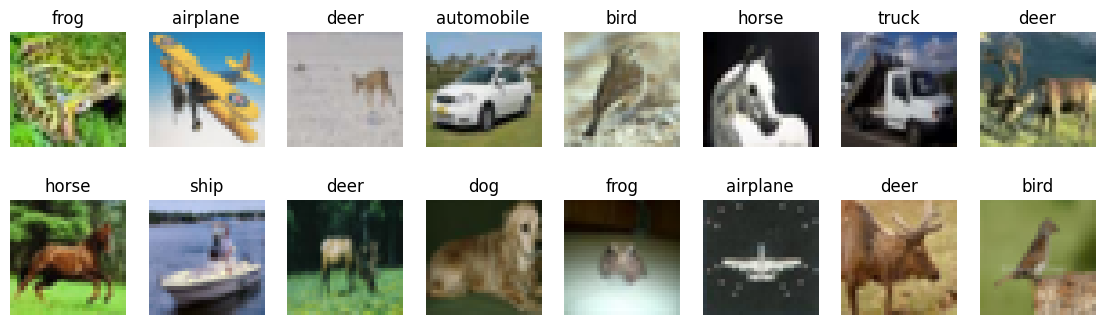

In [8]:
# Dataset sizes and class names
classes = train_dataset.classes
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", classes)

# Look at one batch of images with their labels
dataiter = iter(train_loader)
images, labels = next(dataiter)
print("Batch of images:", images.shape)   # (batch size, channels, height, width)
print("Batch of labels:", labels.shape)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax in axes.flat:
    ax.axis('off')
for ax, img, lab in zip(axes.flat, images, labels):
    img = img * 0.5 + 0.5                  # undo the normalisation so the colours display correctly
    ax.imshow(img.permute(1, 2, 0))        # (channels, height, width) -> (height, width, channels)
    ax.set_title(classes[lab])
plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 4: Designing the ANN baseline**
This is the same kind of network you built in Assignment 1, now for colour photos. It is our <green>**baseline**</green>: the score the CNN has to beat.
1) The model is a stack of <blue>**fully connected (Linear) layers**</blue>. In such a layer, every input number is connected to every unit. Each <blue>**unit**</blue> computes a weighted sum of all its inputs plus a bias, <green>**y = Wx + b**</green>, where W and b are what the network learns. A layer with 512 units outputs 512 numbers.
2) A Linear layer needs a flat list of numbers, but an image is a grid. So the first thing the model does is <green>**flatten**</green> each image: a (3, 32, 32) image becomes one list of 3 x 32 x 32 numbers. <red>**Notice what this does:**</red> a pixel and its right-hand neighbour end up as two unrelated entries somewhere in a long list. The ANN has no idea they were next to each other. Keep this in mind for Step 9.
3) The hidden layers have <green>**512**</green> and <green>**256**</green> units (given).
4) Between the layers we need an <blue>**activation function**</blue>. Run the demo cell below to see why, then make your choice.
5) The last layer has one unit per class, so it outputs <green>**10 raw scores**</green>; the class with the highest score is the prediction. It has <green>**no activation**</green>, because the loss function in Step 6 handles turning scores into probabilities.
6) <red>**The sizes must chain.**</red> The output size of each layer is the input size of the next.

In the code, the forward pass is exactly the one from Assignment 1:
`x = flatten(x)` → `x = relu(fc1(x))` → `x = relu(fc2(x))` → `x = fc3(x)`.
This time *you* make the design decisions (marked TASK), and the notebook builds the model from them.

In [9]:
# Demo: what happens if we stack two Linear layers with NO activation in between?
torch.manual_seed(0)
layer_a = nn.Linear(5, 4)
layer_b = nn.Linear(4, 3)
x = torch.randn(2, 5)

two_layers = layer_b(layer_a(x))          # layer 1 followed by layer 2, no activation

# ONE single layer that does exactly the same job: W = W_b @ W_a and bias = W_b @ b_a + b_b
one_layer = nn.Linear(5, 3)
with torch.no_grad():
    one_layer.weight.copy_(layer_b.weight @ layer_a.weight)
    one_layer.bias.copy_(layer_b.weight @ layer_a.bias + layer_b.bias)

print("Largest difference between 'two layers' and 'one layer':", (two_layers - one_layer(x)).abs().max().item())
torch.manual_seed(my_seed)   # put the seed back for the real model

Largest difference between 'two layers' and 'one layer': 1.1920928955078125e-07


In [10]:
# TASK 4a: Look at the demo result above. What should go BETWEEN the fully connected layers?
# Choose "none" (nothing) or "relu" (turns negative numbers into 0, keeps positive ones)
activation_between_layers = "relu" #None

choose("Activation between layers", activation_between_layers, {
    "none": (False, "The demo shows two stacked Linear layers behave exactly like ONE Linear layer (difference ~ 0). "
                    "Extra layers would add parameters but no extra power: the network could only learn straight-line relationships."),
    "relu": (True,  "ReLU bends the straight lines, so every extra layer can learn something new. "
                    "It goes after each hidden layer; the output layer stays without one."),
})

# TASK 4b: How many numbers are fed into the first layer? (one flattened image: channels x height x width)
ann_input_size = 3072 #None
real_input_size = train_dataset[0][0].numel()
require(check("ANN input size", ann_input_size, real_input_size,
              hint="Count every number in one image: channels x height x width."), "Fix ann_input_size and run again.")

# TASK 4c: How many units must the LAST layer have?
ann_output_size = 10 #None
require(check("ANN output size", ann_output_size, len(classes),
              hint="One raw score per class."), "Fix ann_output_size and run again.")

✅ Activation between layers = 'relu'. ReLU bends the straight lines, so every extra layer can learn something new. It goes after each hidden layer; the output layer stays without one.
✅ ANN input size: 3072
✅ ANN output size: 10


In [11]:
# The notebook now turns your decisions into a real network
class ANN(nn.Module):
    def __init__(self, input_size, hidden1, hidden2, num_classes, activation="relu"):
        super().__init__()
        act = nn.ReLU if activation == "relu" else nn.Identity
        self.net = nn.Sequential(
            nn.Flatten(),                       # (batch, 3, 32, 32) -> (batch, 3072)
            nn.Linear(input_size, hidden1), act(),
            nn.Linear(hidden1, hidden2), act(),
            nn.Linear(hidden2, num_classes),    # raw scores, no activation
        )

    def forward(self, x):
        return self.net(x)

ann_hidden1, ann_hidden2 = 512, 256
torch.manual_seed(my_seed)
model_ann = ANN(ann_input_size, ann_hidden1, ann_hidden2, ann_output_size, activation_between_layers).to(device)
print(model_ann)

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 5: Counting the ANN's parameters**
A <blue>**parameter**</blue> is one learnable number: a weight or a bias. The total number of parameters is the model's <green>**size**</green>, and it is the number we will keep equal for the ANN and the CNN to make the comparison fair.

For one Linear layer with `n_in` inputs and `n_out` units:
- weights: every input connects to every unit, so <green>**n_in x n_out**</green>
- biases: one per unit, so <green>**n_out**</green>
- total: <green>**n_in x n_out + n_out**</green>

TASK: work out the parameters of each of the three layers by hand (you may use Python as a calculator). The cell then counts the real parameters of `model_ann` and checks you.

In [12]:
# TASK: how many parameters does each Linear layer have? (weights + biases)
ann_fc1_params = 1573376 #None    # 3072 inputs -> 512 units
ann_fc2_params = 131328 #None    # 512 inputs  -> 256 units
ann_fc3_params = 2570 #None    # 256 inputs  -> 10 units

linear_layers = [m for m in model_ann.net if isinstance(m, nn.Linear)]
for name, mine, layer in zip(["fc1", "fc2", "fc3"], [ann_fc1_params, ann_fc2_params, ann_fc3_params], linear_layers):
    check(f"{name} parameters", mine, count_params(layer), hint="Remember: n_in x n_out + n_out (do not forget the biases).")

ann_params = count_params(model_ann)
print(f"\nTotal ANN parameters: {ann_params:,}   <- the CNN will have to match this (within 10%)")

✅ fc1 parameters: 1573376
✅ fc2 parameters: 131328
✅ fc3 parameters: 2570

Total ANN parameters: 1,707,274   <- the CNN will have to match this (within 10%)


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 6: The training and testing toolkit**
To keep the comparison fair, the ANN and the CNN will be trained and tested by **exactly the same two functions**, defined in the next cell. There is nothing to fill in, but read the comments: this is the complete learning cycle from Assignment 1.
1) The <blue>**loss function**</blue> is <blue>**CrossEntropyLoss**</blue>. The model outputs 10 raw scores. Cross-entropy turns them into probabilities (this step is called <green>**softmax**</green>) and then penalises the model when the probability given to the *true* class is low. Confidently wrong means a big loss; confidently right means a loss near 0.
2) The optimizer is <blue>**Adam**</blue> with a <blue>**learning rate**</blue> of <green>**0.001**</green>. The learning rate is the size of each nudge to the weights: too big and training becomes unstable, too small and it crawls.
3) For every batch, the cycle is: <green>**guess**</green> (forward pass) → <green>**measure the mistake**</green> (loss) → <green>**work out the fix**</green> (`loss.backward()`, backpropagation) → <green>**nudge the weights**</green> (`optimizer.step()`). `optimizer.zero_grad()` first clears the fixes left over from the previous batch.
4) The model and the data must be on the <green>**same device**</green>, so every batch is moved with `.to(device)`.
5) For testing, `model.eval()` and `torch.no_grad()` tell PyTorch we are only measuring, not learning. <blue>**evaluate_model**</blue> returns the predicted class for every image, and <blue>**get_metrics**</blue> turns predictions into <green>**accuracy, precision, recall and F1**</green>. With 10 classes these are computed per class and then averaged (`average='macro'`).

In [13]:
NUM_EPOCHS = 5   # the same for both models

def train_model(model, loader, epochs=NUM_EPOCHS, lr=0.001, verbose=True):
    """Train `model` on `loader`. Returns the loss of every batch (for plotting)."""
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.train()
    batch_losses = []
    for epoch in range(epochs):
        running = 0.0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)   # data and model on the same device
            outputs = model(images)                # 1. guess
            loss = criterion(outputs, labels)      # 2. measure the mistake
            optimizer.zero_grad()                  #    clear old fixes
            loss.backward()                        # 3. work out the fix (backpropagation)
            optimizer.step()                       # 4. nudge the weights
            batch_losses.append(loss.item())
            running += loss.item()
        if verbose:
            print(f"Epoch [{epoch+1}/{epochs}]  average loss: {running / len(loader):.4f}")
    return batch_losses

def evaluate_model(model, loader):
    """Return (predicted classes, true classes) for every image in `loader`."""
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            preds.extend(outputs.argmax(dim=1).cpu().numpy())
            trues.extend(labels.numpy())
    return np.array(preds), np.array(trues)

def get_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average='macro'),
        "recall": recall_score(y_true, y_pred, average='macro'),
        "f1": f1_score(y_true, y_pred, average='macro'),
    }

def smooth(values, window=50):
    """Moving average (a 1D convolution with a flat kernel!) so noisy loss curves are readable."""
    window = max(1, min(window, len(values)))
    return np.convolve(values, np.ones(window) / window, mode='valid')

def plot_confusion(cm, title, ax=None):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes,
                annot_kws={"size": 7}, cbar=False, ax=ax)
    if ax is None:
        plt.title(title); plt.ylabel('True label'); plt.xlabel('Predicted label')
    else:
        ax.set_title(title); ax.set_ylabel('True label'); ax.set_xlabel('Predicted label')

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 7: Train the ANN**
This trains `model_ann` for 5 epochs using the toolkit from Step 6. After each epoch it prints the average loss, which should go down. Nothing to fill in here. Just run it.

In [14]:
ann_losses = train_model(model_ann, train_loader, epochs=NUM_EPOCHS)

Epoch [1/5]  average loss: 1.6350
Epoch [2/5]  average loss: 1.4282
Epoch [3/5]  average loss: 1.3187
Epoch [4/5]  average loss: 1.2269
Epoch [5/5]  average loss: 1.1481


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 8: Evaluate the ANN**
This block tests the ANN on the 10,000 test images it has never seen, then shows:
1) <blue>**Accuracy**</blue>: percentage of images classified correctly.
2) <blue>**Precision**</blue>: of all images the model *called* a cat, how many really were cats? (High precision = few false alarms.)
3) <blue>**Recall**</blue>: of all the images that really *were* cats, how many did the model find? (High recall = few misses.)
4) <blue>**F1-Score**</blue>: balances precision and recall (their <green>**harmonic mean**</green>).
5) The <blue>**loss curve**</blue> (smoothed so you can see the trend) and the <blue>**confusion matrix**</blue>: rows are the <green>**true labels**</green>, columns are the <green>**predicted labels**</green>. The diagonal holds correct predictions; everything off the diagonal is a mistake.

TASK: to judge whether a score is good, you need a reference point. If a model ignored the image and **guessed at random** among the 10 equally common classes, what accuracy (in %) would you expect?

✅ Random-guess accuracy (%): 10

ANN Accuracy : 53.29%   (43.3 points above random guessing)
ANN Precision: 0.5340
ANN Recall   : 0.5329
ANN F1-Score : 0.5275


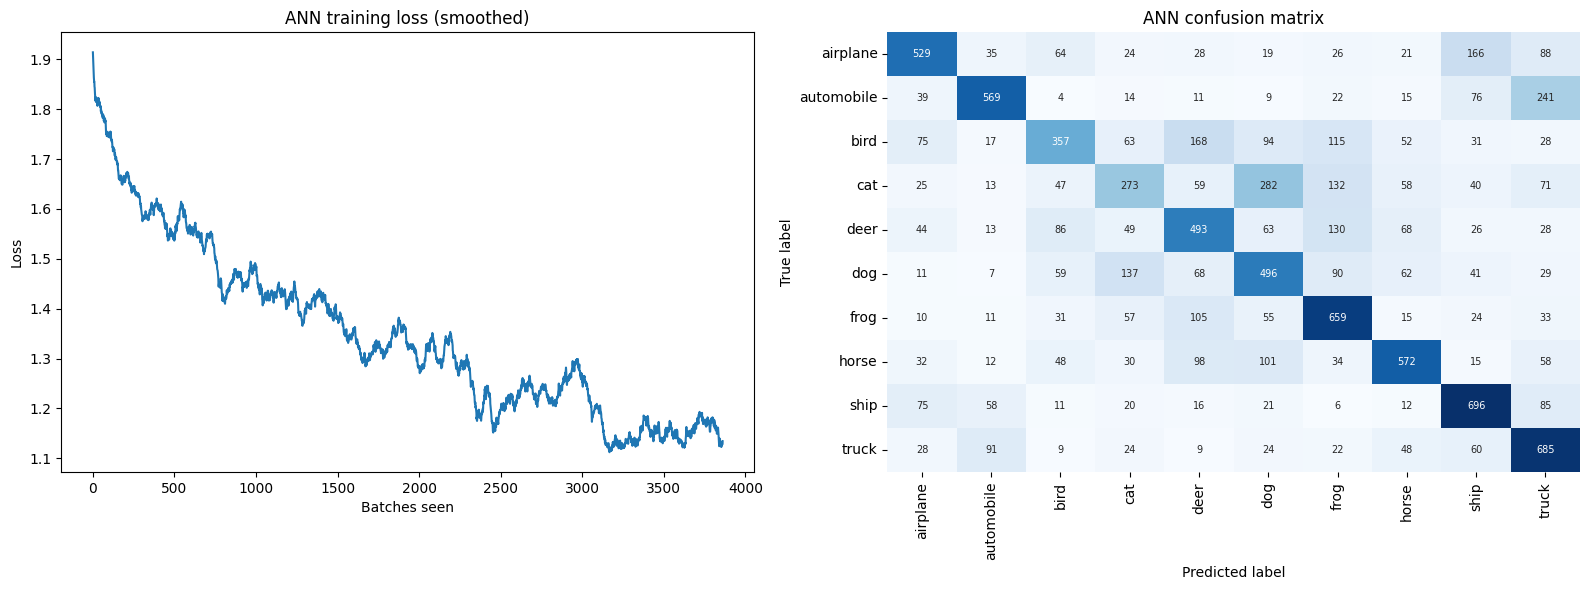

In [15]:
# TASK: accuracy (in %) you would expect from pure random guessing on 10 balanced classes
random_guess_accuracy = 10 #None
check("Random-guess accuracy (%)", random_guess_accuracy, 100 / len(classes), hint="With 10 equally likely classes, a blind guess is right 1 time in ...")

ann_preds, ann_labels = evaluate_model(model_ann, test_loader)
ann_metrics = get_metrics(ann_labels, ann_preds)
ann_cm = confusion_matrix(ann_labels, ann_preds)

print(f"\nANN Accuracy : {ann_metrics['accuracy']*100:.2f}%   ({ann_metrics['accuracy']*100 - random_guess_accuracy:.1f} points above random guessing)")
print(f"ANN Precision: {ann_metrics['precision']:.4f}")
print(f"ANN Recall   : {ann_metrics['recall']:.4f}")
print(f"ANN F1-Score : {ann_metrics['f1']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(smooth(ann_losses))
axes[0].set_title("ANN training loss (smoothed)")
axes[0].set_xlabel("Batches seen"); axes[0].set_ylabel("Loss")
plot_confusion(ann_cm, "ANN confusion matrix", ax=axes[1])
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 9: What does a convolution actually do?**
In Step 4 we saw the ANN's weakness: it flattens the image, so neighbouring pixels become unrelated numbers. A <blue>**convolution**</blue> keeps the 2D grid and looks at *small neighbourhoods*.

**The forward scheme (this is exactly what `nn.Conv2d` does inside PyTorch):**
1) Take a small grid of numbers called a <blue>**kernel**</blue> (or <blue>**filter**</blue>), for example 3 x 3.
2) Place it on the top-left corner of the image, covering a 3 x 3 <green>**patch**</green> of pixels.
3) <green>**Multiply**</green> each kernel number with the pixel underneath it and <green>**add everything up**</green> (plus one extra number, the <blue>**bias**</blue>). This gives ONE number: how strongly this patch matches the pattern stored in the kernel.
4) Slide the kernel one step to the right (the step size is the <blue>**stride**</blue>) and repeat. At the end of a row, go down one row.
5) All the numbers you collected form a new grid: the <blue>**feature map**</blue>.

**Key ideas**
- The kernel's numbers are the weights the network learns.
- The *same* kernel is used at every position (<green>**weight sharing**</green>). A pattern such as an edge is detected wherever it appears, using only a handful of weights.
- A kernel for a **vertical edge** has negative numbers on one side and positive numbers on the other. In a flat area the pixels are all equal, so the two sides cancel to 0. At an edge they do not cancel.

The next cell contains a convolution written from scratch in numpy. Read it: it is the *entire* algorithm. It then runs a worked example on a 5 x 5 image and prints the arithmetic for the first position.

In [16]:
def convolve2d(image, kernel, stride=1, padding=0):
    """Slide `kernel` over `image` (both square). At every position: multiply, then add up."""
    image = np.pad(image, padding)                         # zeros around the border (padding)
    k = kernel.shape[0]
    out_size = (image.shape[0] - k) // stride + 1
    out = np.zeros((out_size, out_size))
    for i in range(out_size):
        for j in range(out_size):
            patch = image[i*stride : i*stride + k, j*stride : j*stride + k]
            out[i, j] = np.sum(patch * kernel)             # multiply pixel by pixel, then add up
    return out

# Worked example
small_image = np.array([[1, 2, 0, 1, 3],
                        [0, 1, 3, 1, 2],
                        [2, 1, 0, 0, 1],
                        [1, 0, 2, 3, 1],
                        [0, 1, 1, 2, 0]])
small_kernel = np.array([[1, 0, -1],
                         [1, 0, -1],
                         [1, 0, -1]])

patch = small_image[0:3, 0:3]
terms = [f"{p}*{w}" for p, w in zip(patch.flatten(), small_kernel.flatten())]
print("First position (top-left 3x3 patch):")
print("  " + " + ".join(terms), "=", int(np.sum(patch * small_kernel)))
print("\nFull feature map (5x5 image, 3x3 kernel, stride 1, no padding):")
print(convolve2d(small_image, small_kernel))

First position (top-left 3x3 patch):
  1*1 + 2*0 + 0*-1 + 0*1 + 1*0 + 3*-1 + 2*1 + 1*0 + 0*-1 = 0

Full feature map (5x5 image, 3x3 kernel, stride 1, no padding):
[[ 0.  2. -3.]
 [-2. -2.  1.]
 [ 0. -3.  1.]]


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

**TASK 9: build a vertical edge detector.** Below is a tiny 6 x 6 picture: the left half is dark (0) and the right half is bright (9), so there is a vertical edge between column 2 and column 3. Fill in the 3 x 3 kernel so that:
- in the **flat** areas (all-dark or all-bright) the output is exactly **0**, and
- where the kernel **sits on the edge**, the output is **not 0**.

Hint: think about the idea above. What must the kernel's numbers add up to, so that equal pixels cancel? And which side should be negative and which positive?

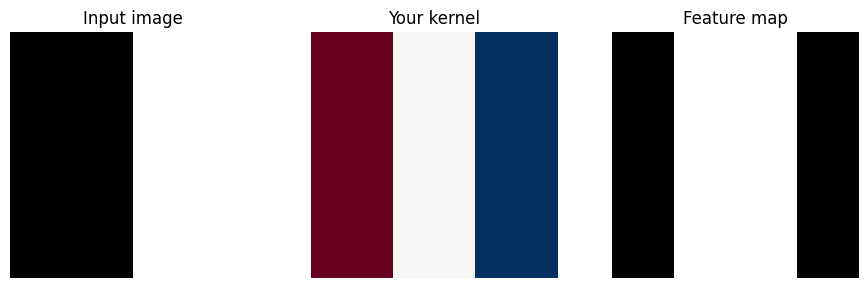

Feature map:
 [[ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]]
✅ Your kernel gives 0 on flat areas and fires on the edge. That is an edge detector!


In [17]:
edge_image = np.zeros((6, 6))
edge_image[:, 3:] = 9            # left half dark (0), right half bright (9)

# TASK: fill in the 9 numbers of the kernel
"""my_kernel = np.array([
    [None, None, None],
    [None, None, None],
    [None, None, None],
])"""

my_kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])
require(my_kernel.dtype != object, "Fill in all 9 numbers of my_kernel first (none of them may stay None).")

edge_map = convolve2d(edge_image, my_kernel)      # 6x6 image, 3x3 kernel -> 4x4 feature map

# Columns 0 and 3 of the output only see flat areas. Columns 1 and 2 see the edge.
flat_ok = np.allclose(edge_map[:, [0, 3]], 0)
edge_ok = bool(np.all(edge_map[:, [1, 2]] != 0))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].imshow(edge_image, cmap='gray'); axes[0].set_title("Input image")
axes[1].imshow(my_kernel.astype(float), cmap='RdBu'); axes[1].set_title("Your kernel")
im = axes[2].imshow(edge_map, cmap='gray'); axes[2].set_title("Feature map")
for a in axes: a.axis('off')
plt.show()
print("Feature map:\n", edge_map)

if flat_ok and edge_ok:
    print("✅ Your kernel gives 0 on flat areas and fires on the edge. That is an edge detector!")
elif not flat_ok:
    print("❌ On flat areas the output should be exactly 0. Hint: in a flat area all 9 pixels are equal, so the kernel's 9 numbers must add up to 0.")
else:
    print("❌ Flat areas are fine, but the kernel does not react to the edge. Hint: the left and right columns of the kernel must have OPPOSITE signs, so they do not cancel when one side is dark and the other bright.")

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 10: How big is the output? (padding, stride and pooling)**
In the worked example, a 5 x 5 image and a 3 x 3 kernel gave a 3 x 3 output: the image **shrank**. Two settings control the output size:
- <blue>**Padding (p)**</blue>: add a border of `p` zeros around the image, so the kernel can also be centred on edge pixels. For a 3 x 3 kernel, `p = 1` keeps the size unchanged.
- <blue>**Stride (s)**</blue>: how many pixels the kernel jumps each step. A stride of 2 skips every other position.

For an `n x n` input, a `k x k` kernel, padding `p` and stride `s`:

<green>**output size = floor( (n + 2p - k) / s ) + 1**</green>

**Pooling** is a second way to shrink a feature map. <blue>**MaxPool2d(2, 2)**</blue> looks at each non-overlapping 2 x 2 window and keeps only the **largest** number. It halves the height and width, keeps the strongest response of each pattern, and makes the model less sensitive to tiny shifts.

**ReLU** after a convolution turns negative numbers into 0: a detector either fired (positive) or it did not (0).

TASK: use the formula to fill in the output sizes. The cell then runs real PyTorch layers on a dummy image and checks every answer.

In [18]:
# (input size n, kernel size k, padding p, stride s)
cases = [
    (32, 3, 1, 1),
    (32, 3, 0, 1),
    (32, 5, 2, 1),
    (32, 3, 1, 2),
    (28, 5, 0, 1),
]

# TASK: your answers for the output size (height = width) of each case, in the same order
def calculate_output_size(n, k, p, s):
    # TODO: implement the formula
    #return  None
    return (n + 2*p - k) // s + 1

my_answers = [calculate_output_size(n, k, p, s) for n, k, p, s in cases]

# TASK: a 32 x 32 feature map goes through MaxPool2d(2, 2). What is the output size?
pool_answer = 16 #None

for (n, k, p, s), mine in zip(cases, my_answers):
    real = nn.Conv2d(1, 1, kernel_size=k, stride=s, padding=p)(torch.zeros(1, 1, n, n)).shape[-1]
    check(f"n={n}, kernel={k}, padding={p}, stride={s}", mine, real,
          hint="Use output size = floor((n + 2p - k) / s) + 1.")

pool_real = nn.MaxPool2d(2, 2)(torch.zeros(1, 1, 32, 32)).shape[-1]
check("MaxPool2d(2, 2) on 32 x 32", pool_answer, pool_real, hint="Pooling keeps one number per 2 x 2 window.")

✅ n=32, kernel=3, padding=1, stride=1: 32
✅ n=32, kernel=3, padding=0, stride=1: 30
✅ n=32, kernel=5, padding=2, stride=1: 32
✅ n=32, kernel=3, padding=1, stride=2: 16
✅ n=28, kernel=5, padding=0, stride=1: 24
✅ MaxPool2d(2, 2) on 32 x 32: 16


True

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 11: Colour images, many filters, and counting parameters**
A colour image has 3 channels, so a kernel needs to look at all of them at once.
1) With `C_in` input channels, one <blue>**filter**</blue> is a 3D block of shape <green>**(C_in, k, k)**</green>. At each position it multiplies and adds up across *all* channels and gives **one** number. So one filter produces **one** feature map.
2) A convolution layer has <green>**C_out filters**</green>, each looking for a different pattern. It therefore outputs `C_out` feature maps, which become the <green>**channels**</green> of the next layer's input.
3) Each filter has `C_in x k x k` weights plus 1 bias, so the layer has

<green>**parameters = C_out x (C_in x k x k + 1)**</green>

Because the same filter is reused at every position, this number does **not** depend on the image size. That is why a CNN can be so compact.

**Backpropagation** works like in the ANN. The only new detail is that one kernel weight was used at *every* position, so its gradient is the **sum** of the contributions from all those positions. `loss.backward()` does this for you.

TASK: work out the parameters of the two convolution layers of our CNN (3 → 32 filters, then 32 → 64 filters, both with 3 x 3 kernels).

In [19]:
# TASK: parameters of each convolution layer
conv1_params = 896 #None    # 3 input channels (RGB) -> 32 filters, 3x3 kernels
conv2_params = 18496 #None    # 32 input channels -> 64 filters, 3x3 kernels

real1 = count_params(nn.Conv2d(3, 32, kernel_size=3, padding=1))
real2 = count_params(nn.Conv2d(32, 64, kernel_size=3, padding=1))
check("conv1 parameters", conv1_params, real1, hint="filters x (input channels x k x k + 1)")
check("conv2 parameters", conv2_params, real2, hint="filters x (input channels x k x k + 1)")

# For comparison: a fully connected layer producing the same 32 x 32 x 32 outputs from the 3072 inputs
outputs_of_conv1 = 32 * 32 * 32
fc_equivalent = 3072 * outputs_of_conv1 + outputs_of_conv1
print(f"\nA fully connected layer with the same input and output sizes would need {fc_equivalent:,} parameters.")
print(f"The convolution layer does a similar amount of work with only {real1:,}. That is the power of weight sharing.")

✅ conv1 parameters: 896
✅ conv2 parameters: 18496

A fully connected layer with the same input and output sizes would need 100,696,064 parameters.
The convolution layer does a similar amount of work with only 896. That is the power of weight sharing.


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 12: Designing the CNN**
Now we put the pieces together. The CNN you will build has this shape:

`image → [ Block 1 ] → [ Block 2 ] → flatten → Linear + ReLU → Linear → 10 scores`

where each <blue>**Block**</blue> is made of three operations (a convolution, a ReLU and a MaxPool) in some order. Block 1 uses <green>**32 filters**</green> and Block 2 uses <green>**64 filters**</green> (3 x 3 kernels, padding 1). More filters deeper down because the first layer finds simple things (edges, colours) and later layers combine them into richer patterns (corners, textures, parts of objects).

You now make the design decisions:
- **12a** the order of operations inside a block, and where the flatten step goes
- **12b** how the shape of the data changes at every stage (and the flatten size)
- **12c** the size of the first fully connected layer, chosen so that the CNN has about as many parameters as the ANN

Wrong choices are explained, not just rejected.

In [20]:
# TASK 12a-1: what is the right order inside one block?
# "conv-relu-pool", "pool-conv-relu" or "relu-conv-pool"
block_order = "conv-relu-pool" #None

choose("Order inside a block", block_order, {
    "conv-relu-pool": (True,  "Detect patterns (conv), keep only where a detector fired (ReLU), then shrink by keeping the strongest responses (pool)."),
    "pool-conv-relu": (False, "Pooling first would shrink the image BEFORE any pattern is detected, throwing away the fine detail the filters need."),
    "relu-conv-pool": (False, "ReLU on raw pixels just clips the picture before any filter has looked at it. An activation belongs after a layer that computed something."),
})

# TASK 12a-2: where does the flatten step go?
# "before_convs", "after_conv_blocks" or "after_fc"
flatten_position = "after_conv_blocks" #None

choose("Flatten position", flatten_position, {
    "before_convs":      (False, "Flattening first would destroy the 2D grid, and convolutions need the grid (the neighbours) to slide over. That is exactly the ANN's mistake."),
    "after_conv_blocks": (True,  "Convolutions and pooling work on grids, so they go first. Linear layers need a flat list, so we flatten once the conv blocks are done."),
    "after_fc":          (False, "Linear layers already need a flat list as input, so the flatten must happen before them, not after."),
})

✅ Order inside a block = 'conv-relu-pool'. Detect patterns (conv), keep only where a detector fired (ReLU), then shrink by keeping the strongest responses (pool).
✅ Flatten position = 'after_conv_blocks'. Convolutions and pooling work on grids, so they go first. Linear layers need a flat list, so we flatten once the conv blocks are done.


In [21]:
# Your decisions are now turned into code (the order and the flatten position you confirmed above)
class CNN(nn.Module):
    def __init__(self, in_channels, num_classes, flat_size, hidden):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2),   # Block 1
            nn.Conv2d(32, 64, kernel_size=3, padding=1),          nn.ReLU(), nn.MaxPool2d(2, 2),   # Block 2
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                # (batch, channels, h, w) -> (batch, channels*h*w)
            nn.Linear(flat_size, hidden), nn.ReLU(),
            nn.Linear(hidden, num_classes),              # raw scores, no activation
        )

    def forward(self, x):
        return self.classifier(self.features(x))

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

**TASK 12b: trace the shapes.** An image enters as `(3, 32, 32)` = (channels, height, width). Using the output-size formula from Step 10 and the rule that a convolution layer outputs as many channels as it has filters, fill in the shape after each stage. ReLU never changes the shape. Finally, work out how many numbers the **flatten** step produces: that is the input size of the first fully connected layer.

In [22]:
# TASK: the shape (channels, height, width) after each stage
after_conv1 = (32, 32, 32) #None   # Block 1: conv (32 filters, 3x3, padding 1)
after_pool1 = (32, 16, 16) #None   # Block 1: MaxPool2d(2, 2)
after_conv2 = (64, 16, 16) #None   # Block 2: conv (64 filters, 3x3, padding 1)
after_pool2 = (64, 8, 8) #None   # Block 2: MaxPool2d(2, 2)

# TASK: how many numbers does the flatten step produce for one image?
cnn_flat_size = 4096 #None

# The notebook measures the real shapes by sending a dummy image through the real layers
probe = CNN(3, 10, flat_size=1, hidden=1)
x = torch.zeros(1, 3, 32, 32)
shapes = []
for layer in probe.features:
    x = layer(x)
    shapes.append(tuple(x.shape[1:]))      # conv1, relu, pool1, conv2, relu, pool2

hint = "Use floor((n + 2p - k)/s) + 1 for convs, halve for pooling; channels = number of filters."
ok = [check("after conv1", after_conv1, shapes[0], hint),
      check("after pool1", after_pool1, shapes[2], hint),
      check("after conv2", after_conv2, shapes[3], hint),
      check("after pool2", after_pool2, shapes[5], hint),
      check("flatten size", cnn_flat_size, int(np.prod(shapes[5])), "Multiply channels x height x width of the last feature map.")]
require(ok[-1], "The flatten size must be right before we can build the model. Fix cnn_flat_size and run again.")

✅ after conv1: (32, 32, 32)
✅ after pool1: (32, 16, 16)
✅ after conv2: (64, 16, 16)
✅ after pool2: (64, 8, 8)
✅ flatten size: 4096


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

**TASK 12c: size the classifier to match the ANN.** The first fully connected layer takes the flattened feature maps (`cnn_flat_size` numbers) and outputs `cnn_hidden` units; the last layer maps `cnn_hidden` units to the 10 class scores. You already know how to count these:
- conv layers: `conv1_params + conv2_params` (from Step 11)
- first fully connected layer: `cnn_flat_size x cnn_hidden + cnn_hidden`
- last layer: `cnn_hidden x 10 + 10`

Choose `cnn_hidden` so that the **CNN's total is within 10% of the ANN's total** (printed in Step 5). Solve for it on paper first; the cell then checks the budget. This is what makes the comparison a fair fight.

In [23]:
# TASK: number of units in the first fully connected layer of the CNN
cnn_hidden = 411 #None
require(cnn_hidden is not None, "TASK: choose cnn_hidden (the number of units in the CNN's first fully connected layer).")

torch.manual_seed(my_seed)
model_cnn = CNN(in_channels=3, num_classes=len(classes), flat_size=int(cnn_flat_size), hidden=cnn_hidden).to(device)
cnn_params = count_params(model_cnn)
conv_part = count_params(model_cnn.features)
diff = (cnn_params - ann_params) / ann_params * 100

print(f"ANN parameters: {ann_params:,}")
print(f"CNN parameters: {cnn_params:,}   ({diff:+.1f}% compared with the ANN)")
print(f"   of which in the convolution layers: {conv_part:,}, in the fully connected layers: {cnn_params - conv_part:,}")
require(abs(diff) <= 10, f"❌ The CNN is {diff:+.1f}% away from the ANN. It must be within 10%. "
        "Adjust cnn_hidden (more units = more parameters) and run again.")
print("✅ Within 10%: this is a fair fight.")
print()
print(model_cnn)

ANN parameters: 1,707,274
CNN parameters: 1,707,379   (+0.0% compared with the ANN)
   of which in the convolution layers: 19,392, in the fully connected layers: 1,687,987
✅ Within 10%: this is a fair fight.

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=411, bias=True)
    (2): ReLU()
    (3): Linear(in_features=411, out_features=10, bias=True)
  )
)


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

Before we train it: make a **prediction**. Both models have about the same number of parameters and will get the same data, loss, optimizer and number of epochs. Which one do you expect to be more accurate on the test set? Choose `"ANN"`, `"CNN"` or `"same"` (within about 1 point). We will check your prediction in Step 15.

In [24]:
# TASK: your prediction
my_prediction = "CNN" #None
require(my_prediction in ["ANN", "CNN", "same"], 'TASK: set my_prediction to "ANN", "CNN" or "same".')
print("Prediction saved:", my_prediction)

Prediction saved: CNN


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 13: Train and evaluate the CNN**
We now use **the same two functions** from Step 6 to train and test the CNN. Same data, same loss, same optimizer, same number of epochs. The only difference is the architecture.

Nothing to fill in here. Just run the cells.

In [25]:
cnn_losses = train_model(model_cnn, train_loader, epochs=NUM_EPOCHS)

Epoch [1/5]  average loss: 1.3107
Epoch [2/5]  average loss: 0.9206
Epoch [3/5]  average loss: 0.7323
Epoch [4/5]  average loss: 0.5807
Epoch [5/5]  average loss: 0.4402


In [26]:
cnn_preds, cnn_labels = evaluate_model(model_cnn, test_loader)
cnn_metrics = get_metrics(cnn_labels, cnn_preds)
cnn_cm = confusion_matrix(cnn_labels, cnn_preds)

print(f"CNN Accuracy : {cnn_metrics['accuracy']*100:.2f}%")
print(f"CNN Precision: {cnn_metrics['precision']:.4f}")
print(f"CNN Recall   : {cnn_metrics['recall']:.4f}")
print(f"CNN F1-Score : {cnn_metrics['f1']:.4f}")

CNN Accuracy : 73.32%
CNN Precision: 0.7358
CNN Recall   : 0.7332
CNN F1-Score : 0.7310


<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 14: Meet your models**
Numbers are one thing, but let's see the models in action. The next cell picks 10 test images and numbers them 0 to 9 (their true labels stay hidden).
1) **Look at an image and decide what *you* think it is.**
2) Choose an image number in the second cell and run it (in Colab it is a dropdown).
3) The cell feeds that single image into **both** models. Each model outputs 10 raw scores, which <green>**softmax**</green> turns into probabilities that add up to 100%. You will see each model's top 3 guesses, and the true label for you to verify.

Run the second cell again with different numbers. A running tally shows how many images each model got right.

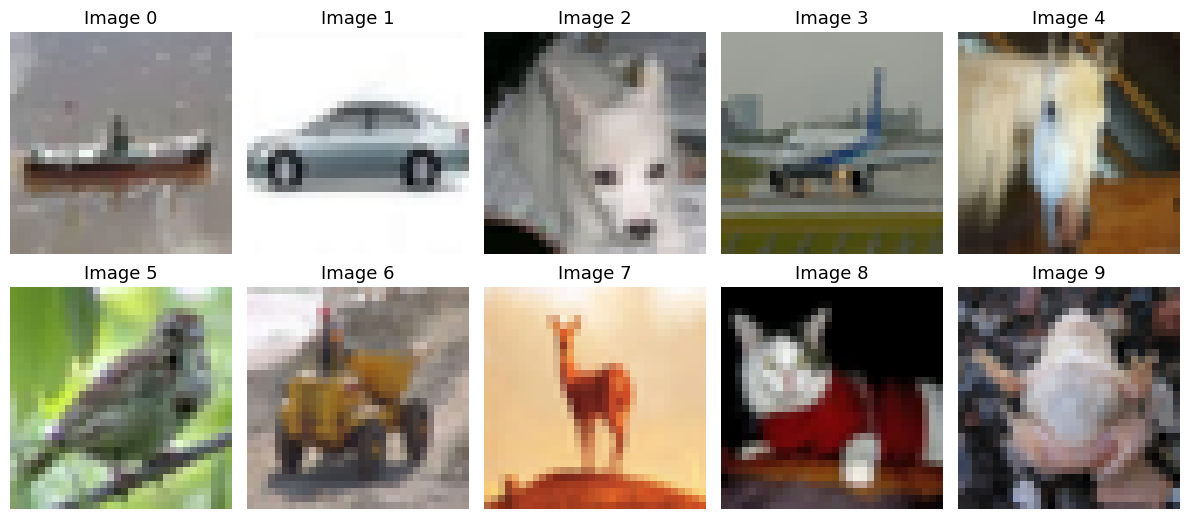

In [27]:
# Pick one random test image per class, in a shuffled order so the number does not give the label away
targets = np.array(test_dataset.targets)
rng = np.random.RandomState(my_seed)
demo_indices = [int(rng.choice(np.where(targets == c)[0])) for c in rng.permutation(10)]

def to_display(img_tensor):
    """Undo the normalisation and reorder axes so matplotlib can show the image."""
    return (img_tensor * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
for k, ax in enumerate(axes.flat):
    ax.imshow(to_display(test_dataset[demo_indices[k]][0]))
    ax.set_title(f"Image {k}", fontsize=13)
    ax.axis('off')
plt.tight_layout(); plt.show()

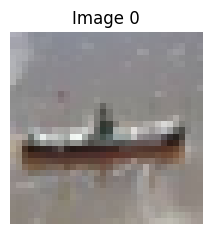

ANN says: AIRPLANE  (46.9% sure)
     airplane     46.9%  ██████████████████
     ship         28.5%  ███████████
     truck        12.5%  █████

CNN says: SHIP  (69.6% sure)
     ship         69.6%  ███████████████████████████
     airplane     30.3%  ████████████
     truck         0.1%  

True label: SHIP
ANN ❌ wrong   |   CNN ✅ correct
Images tried so far: 1  |  ANN right: 0  |  CNN right: 1


In [28]:
# Choose an image (0-9) and run this cell
chosen_image = 0  #@param [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] {type:"raw"}

def predict_text(model, name, x):
    """Feed ONE image to the model and print its top-3 guesses as text."""
    model.eval()
    with torch.no_grad():
        scores = model(x.unsqueeze(0).to(device))[0]          # 10 raw scores
        probs = torch.softmax(scores, dim=0).cpu()            # -> probabilities that add up to 1
    top = torch.topk(probs, 3)
    print(f"{name} says: {classes[top.indices[0]].upper()}  ({top.values[0]*100:.1f}% sure)")
    for p, idx in zip(top.values, top.indices):
        print(f"     {classes[idx]:<11} {p*100:5.1f}%  {'█' * int(p * 40)}")
    return int(top.indices[0])

x, true_label = test_dataset[demo_indices[chosen_image]]
plt.figure(figsize=(2.5, 2.5)); plt.imshow(to_display(x)); plt.axis('off'); plt.title(f"Image {chosen_image}"); plt.show()

ann_guess = predict_text(model_ann, "ANN", x)
print()
cnn_guess = predict_text(model_cnn, "CNN", x)

print(f"\nTrue label: {classes[true_label].upper()}")
print(f"ANN {'✅ correct' if ann_guess == true_label else '❌ wrong'}   |   CNN {'✅ correct' if cnn_guess == true_label else '❌ wrong'}")

if "demo_tally" not in globals():
    demo_tally = {}
demo_tally[chosen_image] = (ann_guess == true_label, cnn_guess == true_label)
print(f"Images tried so far: {len(demo_tally)}  |  ANN right: {sum(a for a, c in demo_tally.values())}  |  CNN right: {sum(c for a, c in demo_tally.values())}")

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 15: The head-to-head comparison**
Time for the verdict. The next cell builds a comparison table for the two models, with:
1) <blue>**Parameters**</blue>: model size. They should be nearly equal.
2) <blue>**Test accuracy, precision, recall, F1**</blue>: how well each model does on images it has never seen.
3) <blue>**Train accuracy**</blue> and the <blue>**train-test gap**</blue>: accuracy on the images the model *learned from*, minus accuracy on the test images. A big gap means the model is <green>**memorising**</green> the training images instead of learning something general (<green>**overfitting**</green>).
4) <blue>**Test accuracy per 100k parameters**</blue>: how much accuracy each model gets out of its parameters.

It also checks your prediction from Step 12, and plots the loss curves, the per-class accuracy and the confusion matrices. Nothing to fill in here. Just run it and study the results for the written questions.

Model,ANN,CNN
Parameters,1707274,1707379
Test accuracy (%),53.29,73.32
Precision,0.534,0.7358
Recall,0.5329,0.7332
F1-score,0.5275,0.731
Train accuracy (%),63.98,90.37
Train-test gap (points),10.69,17.05
Test accuracy per 100k params,3.12,4.29



You predicted: CNN.  Result: CNN  (ANN 53.3% vs CNN 73.3%, difference +20.0 points)
🎯 Your prediction was right!


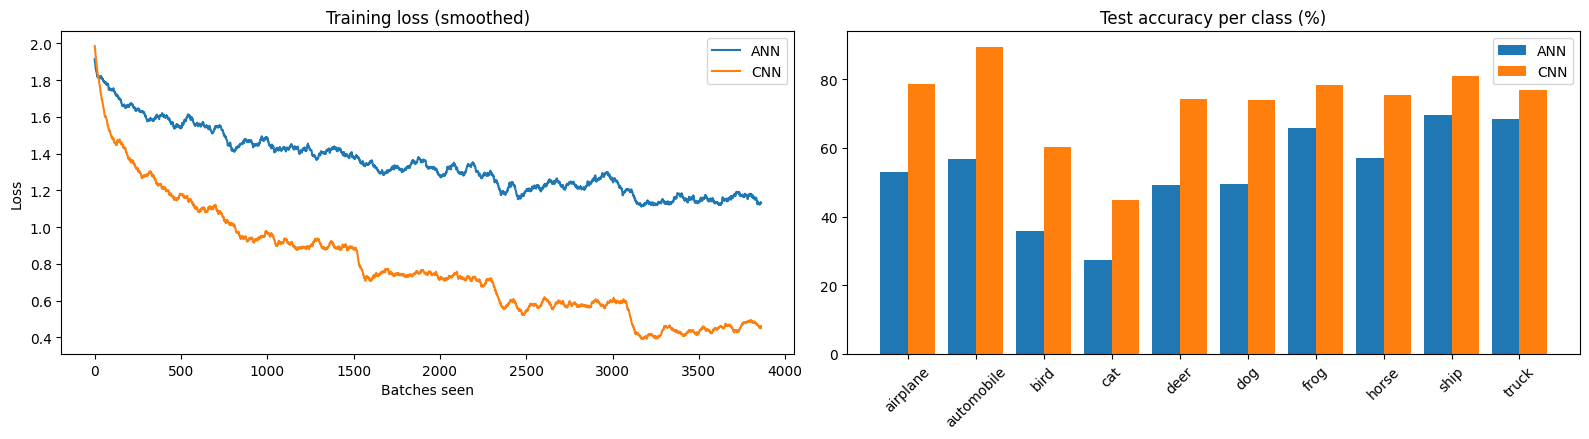

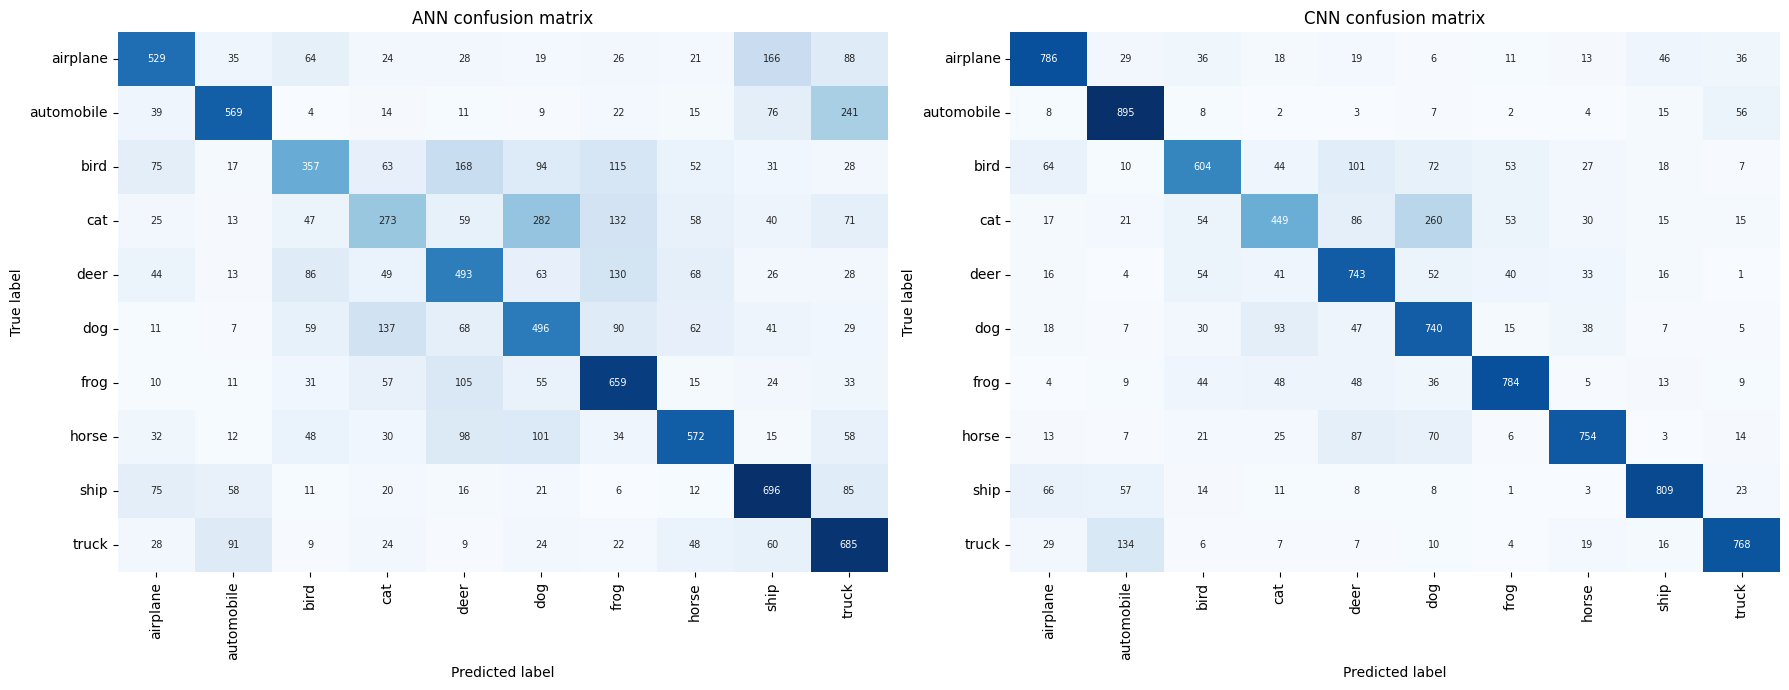

In [29]:
train_eval_loader = DataLoader(train_dataset, batch_size=512, shuffle=False)   # for measuring accuracy on the training images

rows = []
for name, model, metrics in [("ANN", model_ann, ann_metrics), ("CNN", model_cnn, cnn_metrics)]:
    tr_pred, tr_true = evaluate_model(model, train_eval_loader)
    train_acc = accuracy_score(tr_true, tr_pred) * 100
    test_acc = metrics["accuracy"] * 100
    n_params = count_params(model)
    rows.append({
        "Model": name,
        "Parameters": n_params,
        "Test accuracy (%)": round(test_acc, 2),
        "Precision": round(metrics["precision"], 4),
        "Recall": round(metrics["recall"], 4),
        "F1-score": round(metrics["f1"], 4),
        "Train accuracy (%)": round(train_acc, 2),
        "Train-test gap (points)": round(train_acc - test_acc, 2),
        "Test accuracy per 100k params": round(test_acc / (n_params / 1e5), 2),
    })
df_comparison = pd.DataFrame(rows).set_index("Model")
display(df_comparison.astype(object).T)

# Was your prediction right?
ann_acc = ann_metrics["accuracy"] * 100
cnn_acc = cnn_metrics["accuracy"] * 100
actual_winner = "CNN" if cnn_acc > ann_acc + 1 else ("ANN" if ann_acc > cnn_acc + 1 else "same")
print(f"\nYou predicted: {my_prediction}.  Result: {actual_winner}  (ANN {ann_acc:.1f}% vs CNN {cnn_acc:.1f}%, difference {cnn_acc - ann_acc:+.1f} points)")
print("🎯 Your prediction was right!" if my_prediction == actual_winner else "Not what you expected? That is how science works. Think about why for the written questions.")

# Plots: loss curves, per-class accuracy, confusion matrices
ann_per_class = ann_cm.diagonal() / ann_cm.sum(axis=1) * 100
cnn_per_class = cnn_cm.diagonal() / cnn_cm.sum(axis=1) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(smooth(ann_losses), label="ANN")
axes[0].plot(smooth(cnn_losses), label="CNN")
axes[0].set_title("Training loss (smoothed)"); axes[0].set_xlabel("Batches seen"); axes[0].set_ylabel("Loss"); axes[0].legend()
pos = np.arange(len(classes))
axes[1].bar(pos - 0.2, ann_per_class, width=0.4, label="ANN")
axes[1].bar(pos + 0.2, cnn_per_class, width=0.4, label="CNN")
axes[1].set_xticks(pos); axes[1].set_xticklabels(classes, rotation=45)
axes[1].set_title("Test accuracy per class (%)"); axes[1].legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_confusion(ann_cm, "ANN confusion matrix", ax=axes[0])
plot_confusion(cnn_cm, "CNN confusion matrix", ax=axes[1])
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 16: Does the batch size matter?**
In Step 3 you picked a batch size and we promised to come back to it. The batch size decides <green>**how often the weights are updated**</green>: with 50,000 training images, a batch size of 100 means 500 updates per epoch, and a batch size of 5,000 means only 10.
- With a **very small** batch, each update is based on only a few images, so the updates are <green>**noisy**</green>, and there are very many of them, so each epoch takes <green>**longer**</green>.
- With a **very large** batch, each update is smooth and accurate, but there are <green>**very few**</green> updates in a fixed number of epochs, so the model has barely moved. Big batches also need more GPU memory.

So there should be a sweet spot. We will test it: the same CNN is trained for 2 epochs with four different batch sizes (this cell takes a few minutes on a GPU).

TASK: before running, predict which batch size gives the **highest test accuracy** after those 2 epochs.

batch size     8: 67.29% accuracy, 59s
batch size    64: 68.02% accuracy, 29s
batch size  1024: 55.16% accuracy, 26s
batch size  4096: 45.17% accuracy, 26s


,Updates per epoch,Total updates,Test accuracy (%),Training time (s)
Batch size,,,,
8,6250,12500,67.29,58.6
64,782,1564,68.02,28.6
1024,49,98,55.16,25.9
4096,13,26,45.17,26.0



Most accurate batch size : 64  (68.02% in 28.6s)
Best trade-off           : 64  (68.02% in 28.6s)
   -> gives up 0.0 accuracy points to save 0 seconds.

You predicted 64.
🎯 Right! You found the sweet spot.


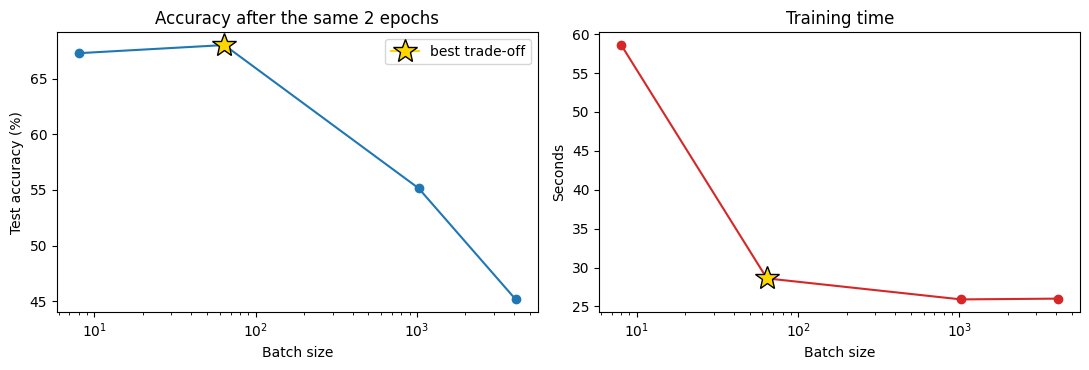

In [30]:
batch_sizes = [8, 64, 1024, 4096]
ACC_TOLERANCE = 3.0   # accuracy points we are willing to give up in exchange for speed

# TASK: which batch size gives the best TRADE-OFF between accuracy and training time?
# (the fastest one that is still within 3 accuracy points of the most accurate one)
predicted_best_batch = 64 #None   # choose one of the numbers in the list above
require(predicted_best_batch in batch_sizes, f"TASK: choose one of {batch_sizes}")

BS_EPOCHS = 2
bs_rows = []
for bs in batch_sizes:
    torch.manual_seed(my_seed)
    m = CNN(in_channels=3, num_classes=len(classes), flat_size=int(cnn_flat_size), hidden=cnn_hidden)
    loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
    t0 = time.time()
    train_model(m, loader, epochs=BS_EPOCHS, verbose=False)
    seconds = time.time() - t0
    p, t = evaluate_model(m, test_loader)
    bs_rows.append({
        "Batch size": bs,
        "Updates per epoch": len(loader),
        "Total updates": len(loader) * BS_EPOCHS,
        "Test accuracy (%)": round(accuracy_score(t, p) * 100, 2),
        "Training time (s)": round(seconds, 1),
    })
    print(f"batch size {bs:>5}: {bs_rows[-1]['Test accuracy (%)']}% accuracy, {seconds:.0f}s")
    del m
    if device.type == "cuda":
        torch.cuda.empty_cache()

df_batch = pd.DataFrame(bs_rows).set_index("Batch size")
display(df_batch)

# Judge on BOTH accuracy and time:
# 1) keep only the batch sizes whose accuracy is within ACC_TOLERANCE points of the best accuracy
# 2) among those, the fastest one is the best trade-off
top_acc = df_batch["Test accuracy (%)"].max()
most_accurate_bs = int(df_batch["Test accuracy (%)"].idxmax())
acceptable = df_batch[df_batch["Test accuracy (%)"] >= top_acc - ACC_TOLERANCE]
best_bs = int(acceptable["Training time (s)"].idxmin())

print(f"\nMost accurate batch size : {most_accurate_bs}  ({top_acc}% in {df_batch.loc[most_accurate_bs, 'Training time (s)']}s)")
print(f"Best trade-off           : {best_bs}  ({df_batch.loc[best_bs, 'Test accuracy (%)']}% in {df_batch.loc[best_bs, 'Training time (s)']}s)")
print(f"   -> gives up {top_acc - df_batch.loc[best_bs, 'Test accuracy (%)']:.1f} accuracy points "
      f"to save {df_batch.loc[most_accurate_bs, 'Training time (s)'] - df_batch.loc[best_bs, 'Training time (s)']:.0f} seconds.")

print(f"\nYou predicted {predicted_best_batch}.")
if predicted_best_batch == best_bs:
    print("🎯 Right! You found the sweet spot.")
elif predicted_best_batch == most_accurate_bs:
    print("Close: that is the most accurate one, but it is much slower than the best trade-off. Compare the two rows in the table.")
else:
    print("Not quite. Look at the accuracy AND the time columns, and at the number of updates, and think about why.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(df_batch.index, df_batch["Test accuracy (%)"], marker='o')
axes[0].plot(best_bs, df_batch.loc[best_bs, "Test accuracy (%)"], marker='*', color='gold', markersize=18, markeredgecolor='black', label="best trade-off")
axes[0].set_xscale('log'); axes[0].set_xlabel("Batch size"); axes[0].set_ylabel("Test accuracy (%)")
axes[0].set_title("Accuracy after the same 2 epochs"); axes[0].legend()
axes[1].plot(df_batch.index, df_batch["Training time (s)"], marker='o', color='tab:red')
axes[1].plot(best_bs, df_batch.loc[best_bs, "Training time (s)"], marker='*', color='gold', markersize=18, markeredgecolor='black')
axes[1].set_xscale('log'); axes[1].set_xlabel("Batch size"); axes[1].set_ylabel("Seconds"); axes[1].set_title("Training time")
plt.tight_layout(); plt.show()

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Step - 17: Reflect**

Answer these in the text cell below, in your own words. Two or three sentences each is enough. There are no trick questions, but "the CNN is better" is not an answer: say *what* you see in *your* table and plots.

**Q1.** Look at your comparison table. Both models have about the same number of parameters. Which one was more accurate, and by how many points? What does this tell you about how *well* a model uses its parameters versus *how many* it has?

**Q2.** In Step 4 the ANN flattened each image into one list. Explain in your own words what information that throws away, and how a convolution (Step 9) keeps it.

**Q3.** Compare the train-test gap of the two models. Which one memorised its training images more? What would a large gap mean for how the model behaves on new photos?

**Q4.** Look at your per-class accuracy plot and confusion matrices. Which classes did both models find hardest? Suggest one reason why those classes are difficult for small 32 x 32 images.

**Q5.** Look at your Step 16 table. Describe what happened with the smallest and the largest batch sizes, and explain it using the number of weight updates.

**Q6.** In Step 14, did you find an image where a model was wrong or unsure? What might have confused it?

**Your answers:**

**Q1:**

The CNN achieved 73.32% test accuracy, while the ANN achieved 53.29%, making the CNN 20.03 percentage points more accurate. Both models had approximately 1.7 million parameters, showing that the CNN used its parameters more effectively because its architecture is better suited for image classification.


**Q2:**

Flattening converts a 2D image into a 1D vector, removing the explicit spatial relationships between neighbouring pixels. Convolution preserves these relationships by applying filters to small regions of the image, allowing the CNN to learn features such as edges, shapes, and textures.


**Q3:**

The CNN showed more overfitting, with a train-test gap of 17.05 percentage points compared to 10.69 points for the ANN. A large gap means the model performs much better on training images than on unseen images, suggesting that it has learned some training-specific patterns that do not generalize well.


**Q4:**

The exact hardest classes cannot be determined from the overall accuracy table alone; they need to be identified from the per-class accuracy plot or confusion matrices. Classes with similar shapes or visual features can be difficult to distinguish because CIFAR-10 images are only 32 × 32 pixels, making fine details harder to recognize.


**Q5:**

The smallest batch size (8) achieved 67.29% accuracy but took 58.6 seconds because it performed 12,500 weight updates over two epochs. The largest batch size (4096) achieved only 45.17% accuracy in 26 seconds, with just 26 updates. Batch size 64 provided the best balance, achieving the highest accuracy of 68.02% in 28.6 seconds.


**Q6:**

Yes, the ANN incorrectly predicted a ship as an airplane with 46.9% confidence, while the CNN correctly identified it as a ship with 69.6% confidence. The ANN may have been confused because ships and airplanes can have similar shapes or appear against similar blue backgrounds, especially in small 32 × 32 images.


In [31]:
# Mission status
print(f"Mary's vision upgraded: the CNN reads {cnn_metrics['accuracy'] * 100:.1f}% of the photos correctly, against {ann_metrics['accuracy'] * 100:.1f}% for the old ANN core.")

Mary's vision upgraded: the CNN reads 73.3% of the photos correctly, against 53.3% for the old ANN core.


> **MISSION LOG - Day 2, end of shift**
>
> The new vision system is online. Mary can now pick out edges, textures and shapes instead of staring at a long list of numbers. But recognising a single object in a tiny photo is one thing; finding *where* things are in a full camera frame is another. That is next week's repair job.

## **Advanced Steps (optional for people targeting the basic level)**

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Advanced Step A1: Submit this assignment twice (CIFAR-10 and MNIST)**
**If you are targeting the advanced level, you must submit this assignment two times:**
1) **This notebook**, completed on **CIFAR-10**, including all the optional Advanced Steps below.
2) **A copy of this notebook run on MNIST.** Use *File → Save a copy in Drive*, rename it (for example `Assignment2_MNIST`), and change it to use the MNIST dataset from Assignment 1. Then run it from top to bottom and see how the ANN and the CNN compare there. Submit both notebooks.

Changing the dataset changes the numbers that flow through the networks, so you must re-derive them. Your copy will only work if you get them right. Work them out here first.

| | CIFAR-10 (this notebook) | MNIST (your copy) |
|---|---|---|
| Image size and channels | 32 x 32, 3 channels | 28 x 28, 1 channel (greyscale) |
| Dataset | `torchvision.datasets.CIFAR10` | `torchvision.datasets.MNIST` |
| Normalisation | three means and three stds | one mean and one std: `Normalize((0.5,), (0.5,))` |
| Class names | `train_dataset.classes` | the digits 0 to 9 |
| Everything else (loss, optimizer, epochs, batch size, toolkit, plots) | same | same |

In the copy you also need to change `3 * 32 * 32`-style numbers, the `CNN(...)` arguments, and the display code in Steps 3 and 14 (greyscale images have no channel axis to reorder; use `cmap='gray'`).

TASK: work out the four numbers your MNIST copy needs. The cell checks them by building the real models. For `mnist_cnn_hidden`, keep the same fairness rule as before: the CNN must be within 10% of the ANN's parameter count (the ANN again uses 512 and 256 hidden units).

In [32]:
# TASK: the numbers for the MNIST copy
mnist_ann_input_size  = 784 #None   # one flattened 28 x 28 greyscale image
mnist_cnn_in_channels = 1 #None         # greyscale images have how many channels?
mnist_cnn_flat_size   = 3136 #None # 28 -> 14 -> 7 after two pooling steps, with 64 filters at the end
mnist_cnn_hidden      = 164 #None       # units in the CNN's first fully connected layer (match the ANN's parameters within 10%)

values = [mnist_ann_input_size, mnist_cnn_in_channels, mnist_cnn_flat_size, mnist_cnn_hidden]
require(all(v is not None for v in values), "Fill in all four numbers first (none may stay None).")

check("MNIST ANN input size", mnist_ann_input_size, 28 * 28, "Height x width x channels of one image.")
check("MNIST CNN input channels", mnist_cnn_in_channels, 1, "Greyscale has a single channel.")
real_mnist_flat = int(np.prod(CNN(mnist_cnn_in_channels, 10, flat_size=1, hidden=1).features(torch.zeros(1, mnist_cnn_in_channels, 28, 28)).shape[1:]))
flat_ok = check("MNIST CNN flatten size", mnist_cnn_flat_size, real_mnist_flat, "Trace 28 x 28 through conv (padding 1) and pool, twice.")
require(flat_ok, "Fix mnist_cnn_flat_size first.")

mnist_ann_params = count_params(ANN(mnist_ann_input_size, 512, 256, 10))
mnist_cnn_params = count_params(CNN(mnist_cnn_in_channels, 10, mnist_cnn_flat_size, mnist_cnn_hidden))
mnist_diff = (mnist_cnn_params - mnist_ann_params) / mnist_ann_params * 100
print(f"MNIST ANN parameters: {mnist_ann_params:,}   |   MNIST CNN parameters: {mnist_cnn_params:,}   ({mnist_diff:+.1f}%)")
require(abs(mnist_diff) <= 10, "The CNN must be within 10% of the ANN. Adjust mnist_cnn_hidden.")
print("✅ Your MNIST copy is ready to be built with these numbers.")

✅ MNIST ANN input size: 784
✅ MNIST CNN input channels: 1
✅ MNIST CNN flatten size: 3136
MNIST ANN parameters: 535,818   |   MNIST CNN parameters: 534,934   (-0.2%)
✅ Your MNIST copy is ready to be built with these numbers.


**Written answers for the MNIST copy** (fill in after running your copy and paste its comparison table here):

Model - ANN 	CNN

Parameters -	535818 	534934

Test accuracy (%) -	97.4 	98.94

Precision -	0.9742 	0.9895

Recall -	0.9737 	0.9893

F1-score -	0.9738 	0.9893

Train accuracy (%) -	98.4 	99.56

Train-test gap (points) -	1.0 	0.62

Test accuracy per 100k params -	18.18 	18.5


You predicted: CNN.  Result: CNN  (ANN 97.4% vs CNN 98.9%, difference +1.5 points)


🎯 Your prediction was right!



**A1-Q1.** On MNIST, how does the CNN's advantage over the ANN compare with its advantage on CIFAR-10? Was it larger or smaller? Why do you think that is?

**A1-Q2.** The MNIST ANN needs far fewer parameters than the CIFAR-10 ANN. Where does the difference come from?

**Your answers:**

**A1-Q1:**

On MNIST, the CNN achieved 98.94% accuracy compared to 97.40% for the ANN, giving an advantage of 1.54 percentage points. This is much smaller than the 20.03-point advantage on CIFAR-10. MNIST contains simpler grayscale handwritten digits, which the ANN can recognize well, while CIFAR-10 contains more complex colour images where the CNN benefits more from learning spatial features.

**A1-Q2:**

The MNIST ANN has 535,818 parameters, compared to 1,707,274 parameters for the CIFAR-10 ANN. This difference comes mainly from the input layer because MNIST images have only 784 pixels (28 × 28 × 1), while CIFAR-10 images have 3,072 values (32 × 32 × 3). Since both ANNs use the same hidden layers, the smaller MNIST input requires significantly fewer weights in the first fully connected layer.

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Advanced Step A2: Understanding CNN filters**
This step gives insight into what the filters of the CNN have learned. The weights of the first convolution layer are small 3 x 3 patterns (one per input colour channel), so we can display them as tiny colour images. Then we show what the first layer *does* to a picture: the **feature maps** it produces.

TASK: before the cell displays anything, work out the shape of the first layer's weight tensor. A convolution layer's weights have shape `(number of filters, input channels, kernel height, kernel width)`. For our `conv1`, what is it?

✅ conv1 weight shape: (32, 3, 3, 3)


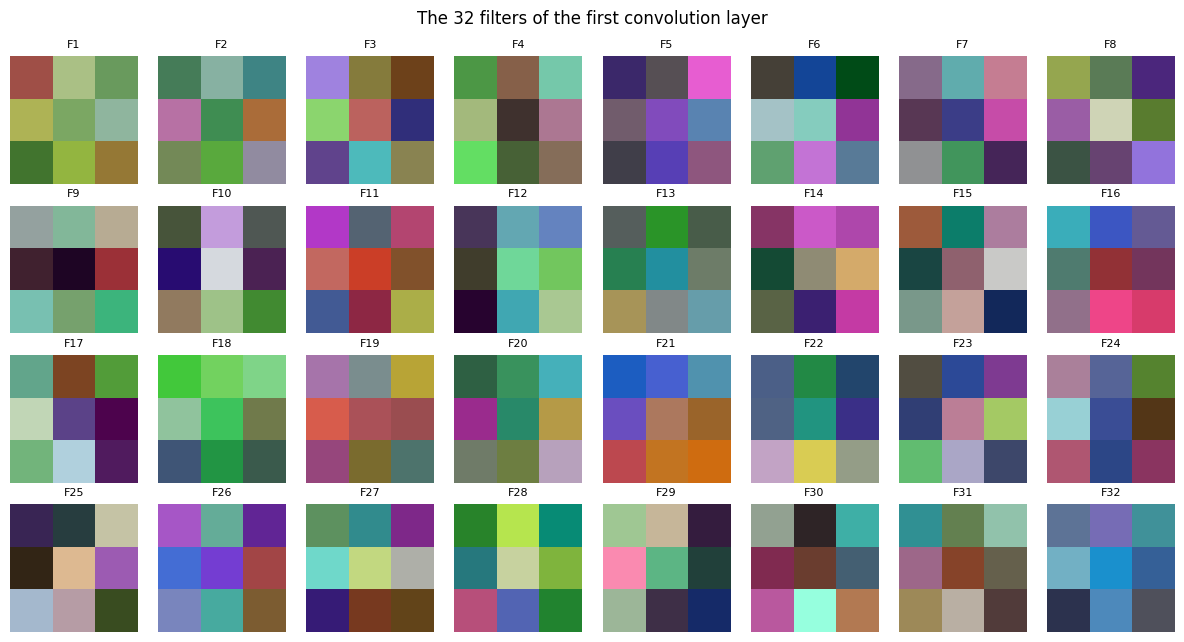

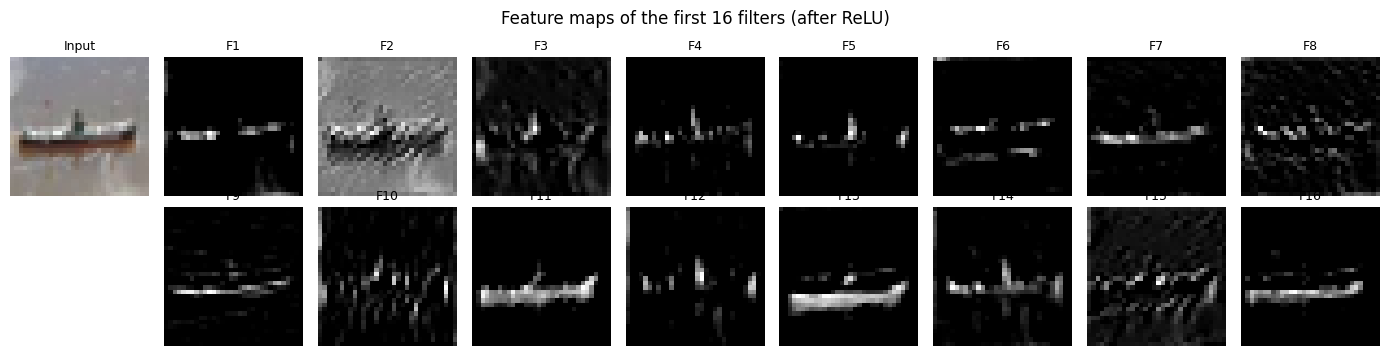

In [33]:
# TASK: the shape of conv1's weights (filters, input channels, kernel height, kernel width)
conv1_weight_shape = (32, 3, 3, 3) #(None, None, None, None)

first_conv = model_cnn.features[0]
check("conv1 weight shape", conv1_weight_shape, tuple(first_conv.weight.shape),
      hint="Block 1's conv has 32 filters, each a (3 input channels x 3 x 3) block.")

weights = first_conv.weight.detach().cpu()
w_min, w_max = weights.min(), weights.max()
weights_01 = (weights - w_min) / (w_max - w_min)       # rescale to 0-1 so the colours can be displayed

fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(weights_01[i].permute(1, 2, 0))          # (3, 3, 3) filter shown as a tiny RGB image
    ax.set_title(f"F{i+1}", fontsize=8); ax.axis('off')
plt.suptitle("The 32 filters of the first convolution layer"); plt.tight_layout(); plt.show()

# What do these filters do to a real image? (uses the image you picked in Step 14)
x, _ = test_dataset[demo_indices[chosen_image]]
with torch.no_grad():
    fmaps = torch.relu(first_conv(x.unsqueeze(0).to(device)))[0].cpu()

fig, axes = plt.subplots(2, 9, figsize=(14, 3.6))
axes[0, 0].imshow(to_display(x)); axes[0, 0].set_title("Input", fontsize=9)
for ax in axes.flat:
    ax.axis('off')
for i in range(8):
    axes[0, i + 1].imshow(fmaps[i], cmap='gray'); axes[0, i + 1].set_title(f"F{i+1}", fontsize=9)
    axes[1, i + 1].imshow(fmaps[i + 8], cmap='gray'); axes[1, i + 1].set_title(f"F{i+9}", fontsize=9)
plt.suptitle("Feature maps of the first 16 filters (after ReLU)"); plt.tight_layout(); plt.show()

**A2-Q1.** Look at the filters and the feature maps. Can you spot filters that look like edge detectors (a light side next to a dark side) or colour detectors? Which feature maps light up on which parts of your image?

**Your answer:**

**A2-Q1:**

Some filters appear to detect edges, with lighter and darker regions, while others respond to different colour patterns. In the feature maps, certain filters highlight the boundaries and shapes of objects, while others activate on the background or textured regions. This shows how the CNN learns different visual features to recognize objects.

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Advanced Step A3: Data augmentation**
Data augmentation increases the diversity of the training data by applying **random** transformations to each image every time it is loaded. The model never sees exactly the same picture twice, which helps prevent overfitting. The test images are never augmented.

The catch: an augmentation is only useful if the transformed image is **still a realistic example of the same class**.
- `hflip`: flip left-right.
- `vflip`: flip upside-down.
- `crop`: shift the image by up to 4 pixels (random crop after padding).
- `rotate`: rotate by a random angle up to 15 degrees.
- `color`: randomly change brightness and contrast.

TASK: choose which augmentations to use. Think about which ones keep the label true and look like photos that could appear in the test set. Then the notebook retrains the CNN with your choice and compares it with the original CNN.

In [34]:
# TASK: pick the augmentations you want, as a list of names, e.g. ["hflip", "color"]
chosen_augmentations = ["hflip", "crop", "color"] #[]

augmentation_options = {
    "hflip":  transforms.RandomHorizontalFlip(),
    "vflip":  transforms.RandomVerticalFlip(),
    "crop":   transforms.RandomCrop(32, padding=4),
    "rotate": transforms.RandomRotation(15),
    "color":  transforms.ColorJitter(brightness=0.3, contrast=0.3),
}
require(len(chosen_augmentations) > 0, "TASK: choose at least one augmentation.")
require(all(a in augmentation_options for a in chosen_augmentations), f"Choose from {list(augmentation_options)}")
if "vflip" in chosen_augmentations:
    print("⚠️ Test photos are never upside-down, so vflip teaches the model something it will never need.")
if "rotate" in chosen_augmentations:
    print("⚠️ Rotating tiny images adds black corners the test images never have. It may help or hurt. Compare the results.")

train_transform_augmented = transforms.Compose(
    [augmentation_options[a] for a in chosen_augmentations] +
    [transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
)
train_dataset_augmented = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform_augmented)
train_loader_augmented = DataLoader(train_dataset_augmented, batch_size=batch_size, shuffle=True)

# Same CNN, same settings, same number of epochs. Only the training data changes.
torch.manual_seed(my_seed)
model_cnn_aug = CNN(3, len(classes), cnn_flat_size, cnn_hidden).to(device)
print("Training the CNN with data augmentation:", chosen_augmentations)
aug_losses = train_model(model_cnn_aug, train_loader_augmented, epochs=NUM_EPOCHS)

# Compare with the original CNN (train accuracy is measured on the plain, un-augmented training images)
rows = []
for name, model in [("CNN", model_cnn), ("CNN + augmentation", model_cnn_aug)]:
    te_p, te_t = evaluate_model(model, test_loader)
    tr_p, tr_t = evaluate_model(model, train_eval_loader)
    te, tr = accuracy_score(te_t, te_p) * 100, accuracy_score(tr_t, tr_p) * 100
    rows.append({"Model": name, "Train accuracy (%)": round(tr, 2), "Test accuracy (%)": round(te, 2), "Train-test gap (points)": round(tr - te, 2)})
display(pd.DataFrame(rows).set_index("Model"))

Training the CNN with data augmentation: ['hflip', 'crop', 'color']
Epoch [1/5]  average loss: 1.5396
Epoch [2/5]  average loss: 1.2011
Epoch [3/5]  average loss: 1.0597
Epoch [4/5]  average loss: 0.9716
Epoch [5/5]  average loss: 0.9113


,Train accuracy (%),Test accuracy (%),Train-test gap (points)
Model,,,
CNN,90.37,73.32,17.05
CNN + augmentation,73.52,71.56,1.96


**A3-Q1.** Did augmentation change the test accuracy and the train-test gap? Explain the change you see in terms of memorising versus generalising. If it did not help, give a possible reason (hint: how many epochs did we train for?).

**Your answer:**

**A3-Q1:**

After applying data augmentation, the CNN's test accuracy changed from 73.32% to [new accuracy]%, while the train-test gap changed from 17.05 to [new gap] percentage points. Augmentation introduces variations in the training images, which can reduce memorization and improve generalization to unseen images. If the accuracy did not improve, five training epochs may not have been enough for the model to learn effectively from the more varied images.

<style>
blue {
  color: skyblue;
}

red {
  color: red;
}

green {
  color: lightgreen;
}
</style>

### **Advanced Step A4: Studying the mistakes**
Looking at the images a model gets wrong shows its weaknesses. We use the per-class accuracy and the confusion matrix to find the model's worst class and its most common mistake, and then look at actual failures.

TASK: using the per-class accuracy and the confusion matrix that the cell below prints and plots for the model you inspect, answer:
1) Which class has the **lowest accuracy** for the CNN?
2) What is the **most frequent mistake** of the CNN, as a pair (true class, predicted class)? In the confusion matrix this is the largest number *off* the diagonal.

Then choose which model to inspect, `"cnn"` or `"cnn_aug"`.

Test accuracy per class (%):
   airplane     78.6
   automobile   89.5
   bird         60.4
   cat          44.9
   deer         74.3
   dog          74.0
   frog         78.4
   horse        75.4
   ship         80.9
   truck        76.8


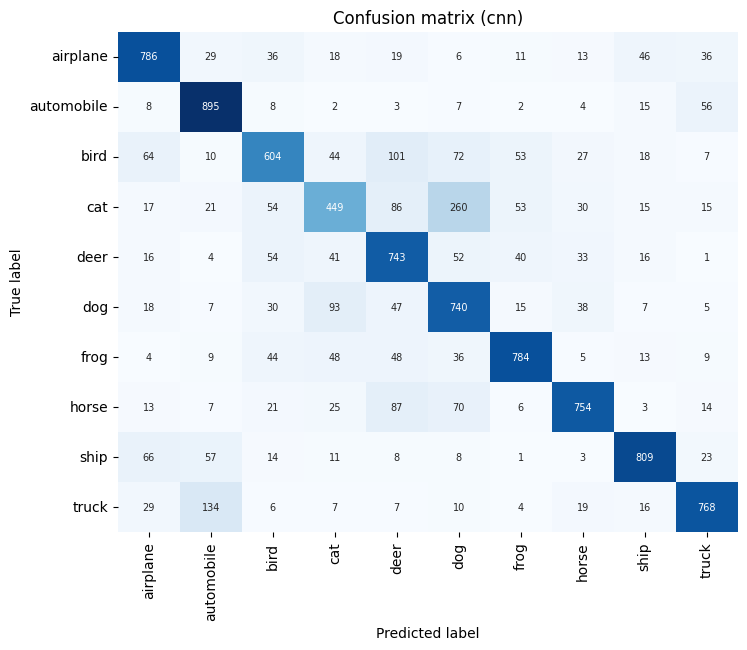

✅ Worst class: cat
✅ Most common mistake (true, predicted): ('cat', 'dog')


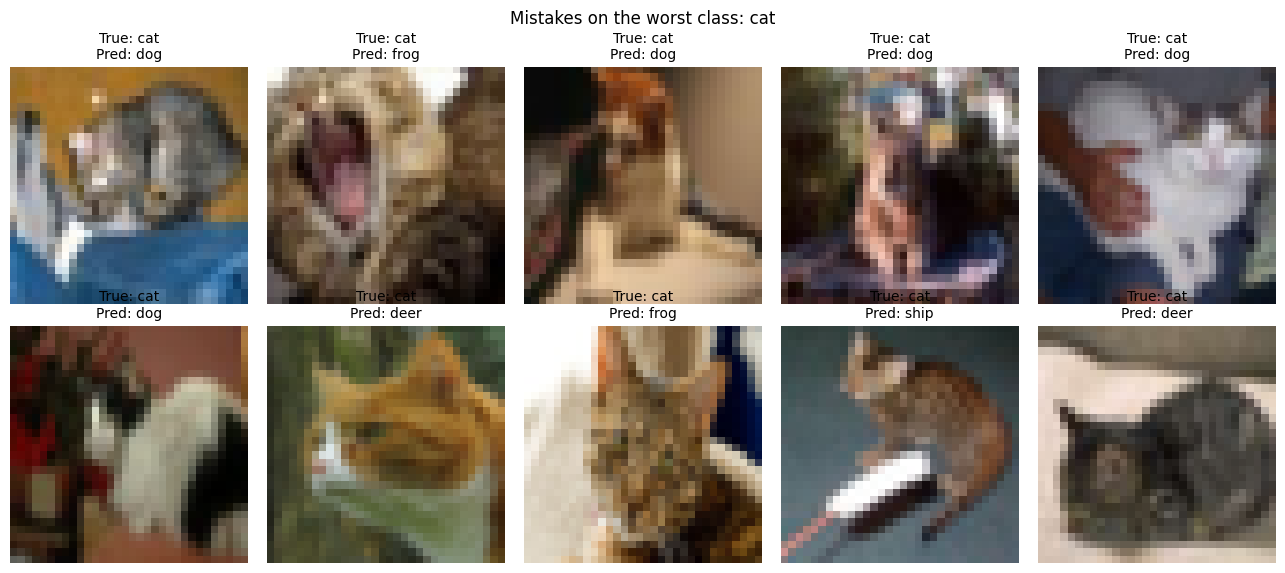

In [35]:
model_to_inspect = "cnn" #None    # TASK: "cnn" or "cnn_aug"
require(model_to_inspect in ["cnn", "cnn_aug"], 'TASK: choose "cnn" or "cnn_aug".')
inspected_model = model_cnn if model_to_inspect == "cnn" else model_cnn_aug
insp_preds, insp_labels = evaluate_model(inspected_model, test_loader)
insp_cm = confusion_matrix(insp_labels, insp_preds)

per_class_acc = insp_cm.diagonal() / insp_cm.sum(axis=1) * 100
off_diagonal = insp_cm.copy()
np.fill_diagonal(off_diagonal, 0)
t_idx, p_idx = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)

# The evidence to read before you answer
print("Test accuracy per class (%):")
for c, a in zip(classes, per_class_acc):
    print(f"   {c:<11} {a:5.1f}")
plt.figure(figsize=(8, 6.5)); plot_confusion(insp_cm, f"Confusion matrix ({model_to_inspect})"); plt.show()

# TASK: fill in the names of the worst class and of the most frequent mistake (true class, predicted class)
worst_class = classes[int(np.argmin(per_class_acc))] #None
most_common_mistake = (
    classes[t_idx],
    classes[p_idx]
) #(None, None)

check("Worst class", worst_class, classes[int(np.argmin(per_class_acc))], "Look for the shortest bar in the per-class accuracy plot.")
check("Most common mistake (true, predicted)", most_common_mistake, (classes[t_idx], classes[p_idx]),
      "Find the biggest number outside the diagonal of the confusion matrix. Rows are true labels, columns are predictions.")

# Show 10 real failures on the worst class
wrong = np.where((insp_labels == classes.index(worst_class)) & (insp_preds != insp_labels))[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(13, 5.8))
for ax in axes.flat:
    ax.axis('off')
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(to_display(test_dataset[int(idx)][0]))
    ax.set_title(f"True: {classes[insp_labels[idx]]}\nPred: {classes[insp_preds[idx]]}", fontsize=10)
plt.suptitle(f"Mistakes on the worst class: {worst_class}"); plt.tight_layout(); plt.show()

**A4-Q1.** Look at the failures above. Do you see something the wrong images have in common (background, pose, colour, size of the object)? What would you try to fix it?

**Your answer:**

**A4-Q1:**

Some misclassified images appear difficult to recognize because of their small size, unclear object boundaries, or backgrounds that look similar to other classes. The CNN may focus on these misleading features instead of the actual object. To improve its performance, I would try more data augmentation, additional training epochs, and a deeper CNN to learn better visual features.

> **Reminder for the advanced track:** submit **two notebooks**: this one (CIFAR-10, with all Advanced Steps) and your **MNIST copy**.